#Problematica 3

In [ ]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 109.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 85.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 63.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 65.3 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu1

 #### Cómo podría la distribución etaria en las comunas influir indirectamente en la capacidad de respuesta hospitalaria, y, con ello, en la gravedad de los siniestros viales?

In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
from shapely import wkt
from sklearn.preprocessing import KBinsDiscretizer
from imblearn.over_sampling import SMOTE
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination
import matplotlib.pyplot as plt
import seaborn as sns

#### Cargamos datos

In [ ]:
df_accidentes = pd.read_csv("/content/accidentes.csv")
df_accidentes["geometry"] = df_accidentes["geometry"].apply(wkt.loads)
gdf_accidentes = gpd.GeoDataFrame(df_accidentes, geometry="geometry", crs="EPSG:32719").to_crs(epsg=4326)

df_rutas = pd.read_csv("/content/rutas.csv")

df_hospitales = pd.read_csv("/content/hospitales.csv")
df_hospitales["geometry"] = df_hospitales["geometry"].apply(wkt.loads)
gdf_hospitales = gpd.GeoDataFrame(df_hospitales, geometry="geometry", crs="EPSG:3857").to_crs(epsg=4326)

#### Variables

In [ ]:
dist_min = df_rutas.groupby("ID")["path_length"].min().reset_index()
dist_min.columns = ["ID", "min_path_length"]
gdf_accidentes = gdf_accidentes.merge(dist_min, how="left", on="ID")

cols_edad = ["EDAD_0A5", "EDAD_6A14", "EDAD_15A64", "EDAD_65YMAS"]
features_bayes = cols_edad + ["estimated_time_minutes", "min_path_length"]

X_bayes = gdf_accidentes[features_bayes].copy()
y_bayes = gdf_accidentes["Gravedad"]

#### Balance de gravedad (para el SMOTE) y eliminamos los NaN

In [ ]:
total = len(gdf_accidentes)
for val, count in y_bayes.value_counts().items():
    pct = count / total * 100
    print(f"Gravedad = {val}: {count} casos ({pct:.2f}%)")

#Eliminar NaN
Xy_bayes = pd.concat([X_bayes, y_bayes], axis=1)
Xy_bayes_clean = Xy_bayes.dropna()

X_bayes_clean = Xy_bayes_clean[features_bayes]
y_bayes_clean = Xy_bayes_clean["Gravedad"]


Gravedad = 0: 15092 casos (87.75%)
Gravedad = 1: 2106 casos (12.25%)


### SMOTE

In [ ]:
df_bayes_no_smote = X_bayes_clean.copy()
df_bayes_no_smote["Gravedad"] = y_bayes_clean.values

smote = SMOTE(random_state=42)
X_bayes_smote, y_bayes_smote = smote.fit_resample(X_bayes_clean, y_bayes_clean)

print("\nNuevo balance después de SMOTE:")
for val, count in pd.Series(y_bayes_smote).value_counts().items():
    pct = count / len(y_bayes_smote) * 100
    print(f"Gravedad = {val}: {count} casos ({pct:.2f}%)")


Nuevo balance después de SMOTE:
Gravedad = 0: 14905 casos (50.00%)
Gravedad = 1: 14905 casos (50.00%)


### Discretizamos

In [ ]:
n_bins = 4
kbd = KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy='quantile')

X_disc_smote = kbd.fit_transform(X_bayes_smote)
df_bayes_smote_disc = pd.DataFrame(X_disc_smote, columns=features_bayes)
df_bayes_smote_disc["Gravedad"] = y_bayes_smote.values

### Red bayesiana

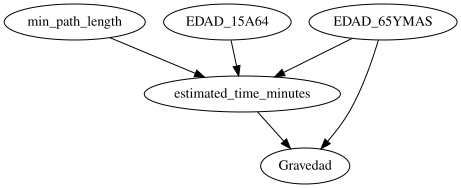

In [14]:
from graphviz import Digraph

dot = Digraph()

dot.node("A", "EDAD_65YMAS")
dot.node("B", "estimated_time_minutes")
dot.node("C", "Gravedad")
dot.node("D", "min_path_length")
dot.node("E", "EDAD_15A64")

dot.edge("A", "B")
dot.edge("A", "C")
dot.edge("E", "B")
dot.edge("D", "B")
dot.edge("B", "C")

dot.render("bayes_net_problem3", format="png", cleanup=False)
dot


In [ ]:
edges = [
    ("EDAD_65YMAS", "estimated_time_minutes"),
    ("EDAD_15A64", "estimated_time_minutes"),
    ("estimated_time_minutes", "Gravedad"),
    ("min_path_length", "estimated_time_minutes"),
    ("EDAD_65YMAS", "Gravedad")
]

model = DiscreteBayesianNetwork(edges)
model.fit(df_bayes_smote_disc)


### Inferencia

In [ ]:
infer = VariableElimination(model)

### Tabla de inferencia multinivel

In [ ]:
tiempos_bins = [0, 1, 2, 3]
edad_bins = [0, 1, 2, 3]

tabla_resultados = []

for t_bin in tiempos_bins:
    for e_bin in edad_bins:
        q = infer.query(variables=["Gravedad"], evidence={
            "estimated_time_minutes": t_bin,
            "EDAD_65YMAS": e_bin
        })
        p_g1 = q.values[1]

        tabla_resultados.append({
            "Tiempo_bin": t_bin,
            "Edad_65YMAS_bin": e_bin,
            "P_Gravedad1": round(p_g1, 4)
        })

tabla_df = pd.DataFrame(tabla_resultados)
print("\n========== Tabla de Inferencia Problemática 3 ==========")
print(tabla_df)


========== Tabla de Inferencia Problemática 3 ==========
    Tiempo_bin  Edad_65YMAS_bin  P_Gravedad1
0            0                0       0.4793
1            0                1       0.4735
2            0                2       0.4523
3            0                3       0.5241
4            1                0       0.4329
5            1                1       0.5417
6            1                2       0.5984
7            1                3       0.5260
8            2                0       0.4816
9            2                1       0.5326
10           2                2       0.4945
11           2                3       0.4944
12           3                0       0.4770
13           3                1       0.5190
14           3                2       0.4537
15           3                3       0.4127


### HEATMAP

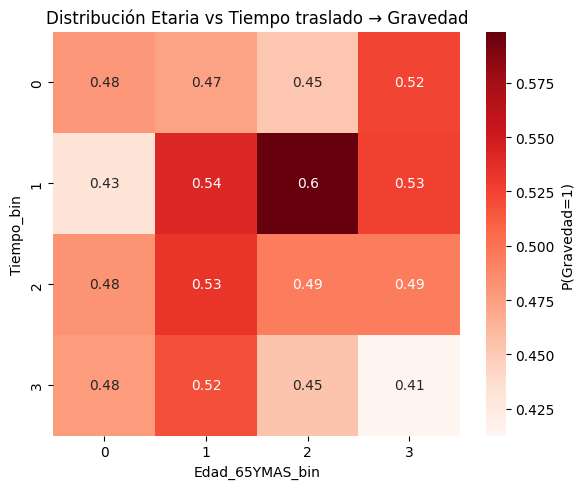

In [ ]:
pivot = tabla_df.pivot(index="Tiempo_bin", columns="Edad_65YMAS_bin", values="P_Gravedad1")

plt.figure(figsize=(6,5))
sns.heatmap(pivot, annot=True, cmap="Reds", cbar_kws={'label': 'P(Gravedad=1)'})
plt.title("Distribución Etaria vs Tiempo traslado → Gravedad")
plt.xlabel("Edad_65YMAS_bin")
plt.ylabel("Tiempo_bin")
plt.tight_layout()
plt.show()

# Conclusión

A partir del análisis mediante redes bayesianas, se observa que la distribución etaria en las comunas influye de manera indirecta en la gravedad de los siniestros viales, a través de su efecto sobre la capacidad de respuesta hospitalaria.

En particular, las comunas con una mayor proporción de población de 65 años o más tienden a presentar mayores tiempos de traslado a servicios de urgencia, lo que se asocia a una mayor probabilidad de siniestros graves (fallecidos y heridos graves).

El modelo muestra que la interacción entre tiempos de traslado elevados y alta presencia de adultos mayores amplifica el riesgo de gravedad, sugiriendo que la estructura demográfica de las comunas es un factor relevante a considerar en la planificación de recursos hospitalarios y estrategias de respuesta rápida.